# Carga de los datos

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from utils import (AZUL, NARANJA, GRIS_TEXTO, GRIS_GRILLA, DIVERGENTE,
                   aplicar_estilo, hexbin_par, escala_comun, banda_por_hora)

In [2]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'
OUT = '../data/out/bivariadas/'

# Paleta, colormaps y funciones de gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}  # se exportan todas al final

In [3]:
df = pd.read_csv(PROCESSED + '/mediciones_limpias.csv')
df.head(5)

,station_id,target_hour_utc,horizonte_horas,obs_timestamp,fcst_target_timestamp,fcst_generated_at,obs_temp_c,fcst_temp_c,obs_heat_index_c,obs_rh_pct,...,categoria,hora_local,error_temp_c,abs_error_temp_c,error_rh_pct,abs_error_rh_pct,error_dewpoint_c,abs_error_dewpoint_c,error_windspeed_kmh,abs_error_windspeed_kmh
0,057CE,2026-10-19T17,6,2026-10-19 17:10:00+00:00,2026-10-19 17:00:00+00:00,2026-10-19 11:00:00+00:00,24.34,22.22,24.250812,54.431107,...,ok,12,-2.12,2.12,4.568893,4.568893,-0.671111,0.671111,3.994,3.994
1,BDWM4,2026-10-21T12,6,2026-10-21 12:32:00+00:00,2026-10-21 12:00:00+00:00,2026-10-21 06:00:00+00:00,-1.11,3.33,NaN,91.012237,...,ok,8,4.44,4.44,3.987763,3.987763,5.167778,5.167778,3.220,3.220
2,E7246,2026-10-21T12,6,2026-10-21 12:30:00+00:00,2026-10-21 12:00:00+00:00,2026-10-21 06:00:00+00:00,2.78,8.33,NaN,86.868260,...,intermitente,6,5.55,5.55,13.131740,13.131740,7.523333,7.523333,0.000,0.000
3,F3284,2026-10-21T12,6,2026-10-21 12:30:00+00:00,2026-10-21 12:00:00+00:00,2026-10-21 06:00:00+00:00,10.00,8.89,NaN,73.245166,...,intermitente,7,-1.11,1.11,-3.245166,3.245166,-1.541111,1.541111,9.660,9.660
4,ARD06,2026-10-19T17,6,2026-10-19 17:30:00+00:00,2026-10-19 17:00:00+00:00,2026-10-19 11:00:00+00:00,23.44,21.11,22.860360,39.094649,...,intermitente,12,-2.33,2.33,-1.094649,1.094649,-2.618889,2.618889,-1.548,1.548


In [4]:
print(df.columns)

Index(['station_id', 'target_hour_utc', 'horizonte_horas', 'obs_timestamp',
       'fcst_target_timestamp', 'fcst_generated_at', 'obs_temp_c',
       'fcst_temp_c', 'obs_heat_index_c', 'obs_rh_pct', 'fcst_rh_pct',
       'obs_wind_direction_d', 'obs_windspeed_kmh', 'fcst_windspeed_kmh',
       'obs_dewpoint_c', 'fcst_dewpoint_c', 'fcst_pop_pct', 'fecha_particion',
       'hora_particion', 'estado', 'timeZone', 'latitud', 'longitud',
       'elevation', 'red', 'categoria', 'hora_local', 'error_temp_c',
       'abs_error_temp_c', 'error_rh_pct', 'abs_error_rh_pct',
       'error_dewpoint_c', 'abs_error_dewpoint_c', 'error_windspeed_kmh',
       'abs_error_windspeed_kmh'],
      dtype='str')


# Limpieza de datos

`mediciones_limpias.csv` ya tiene los apóstrofos corregidos, los valores imposibles descartados (sección 1 de
`relaciones-bivariadas.ipynb`) y los atributos de estación. Lo que falta para poder hacer ACF/estacionariedad es específico
de series temporales:

1. **Regularizar el índice temporal** por estación (ahora mismo las filas de estaciones distintas vienen intercaladas y,
   dentro de cada estación, faltan horas enteras -no sólo valores vacíos en filas existentes).
2. **Detectar y entender los huecos** antes de decidir cómo tratarlos: no son todos iguales.
3. **Filtrar las estaciones** a un cohorte con intermitencia manejable para trabajar serie por serie.
4. **Corregir saltos horarios imposibles** (un atípico temporal, distinto de los outliers obs-vs-pronóstico ya filtrados).
5. **Imputar de forma acotada** (sólo huecos cortos) y dejar un flag de qué se imputó.
6. **Discretizar la dirección del viento** en sectores y codificar la hora de forma cíclica.

### 1. Ordenar y medir el rango temporal del proyecto

In [5]:
df['target_hour_utc'] = pd.to_datetime(df['target_hour_utc'], utc=True)
df = df.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

RANGO_COMPLETO = pd.date_range(df['target_hour_utc'].min(), df['target_hour_utc'].max(), freq='h')
print(f'Rango del proyecto: {RANGO_COMPLETO.min()} a {RANGO_COMPLETO.max()} ({len(RANGO_COMPLETO)} horas)')

Rango del proyecto: 2026-10-19 02:00:00+00:00 a 2026-11-02 21:00:00+00:00 (356 horas)


### 2. Cobertura y huecos por estación

Por estación: cuántas horas tiene sobre las {len(RANGO_COMPLETO)} posibles, y cuál es el hueco (sin ninguna fila) más largo.

In [6]:
def resumen_cobertura(g):
    huecos = g['target_hour_utc'].diff().dt.total_seconds().div(3600).dropna()
    return pd.Series({
        'n_horas': len(g),
        'cobertura_pct': 100 * len(g) / len(RANGO_COMPLETO),
        'hueco_max_h': huecos.max() if len(huecos) else np.nan,
    })

cobertura = df.groupby('station_id').apply(resumen_cobertura)
atributos_estacion = df.groupby('station_id')[['estado', 'timeZone', 'latitud', 'longitud', 'elevation', 'red', 'categoria']].first()
cobertura = cobertura.join(atributos_estacion)
cobertura['hueco_max_h'].describe()

count    498.000000
mean      43.345382
std       50.523150
min        5.000000
25%       11.000000
50%       11.000000
75%      120.000000
max      304.000000
Name: hueco_max_h, dtype: float64

El hueco máximo no crece de forma gradual: salta de ~11 h (mediana) a ~120 h (percentil 75). Es una distribución
bimodal, no un espectro continuo de intermitencia -conviene mirarla antes de elegir un umbral.

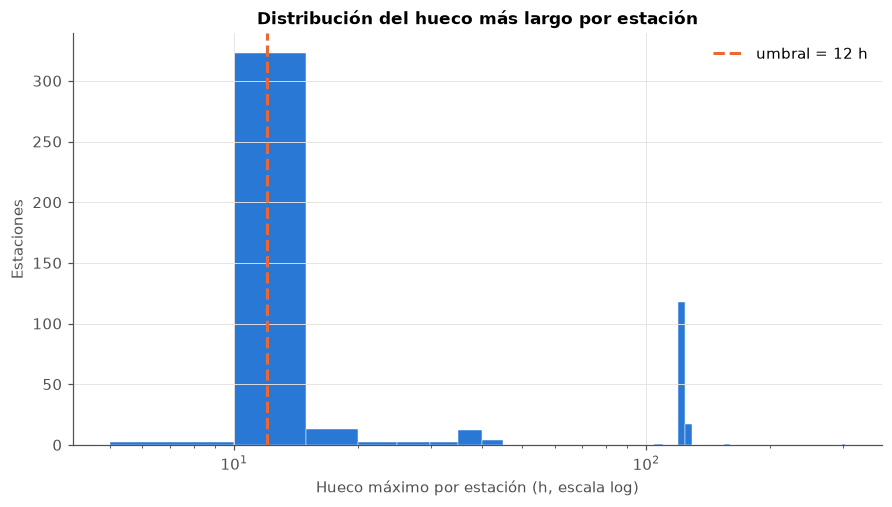

In [7]:
UMBRAL_HUECO = 12  # horas; separa el cluster de huecos "normales" (1-11 h) del salto a ~120 h

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(cobertura['hueco_max_h'], bins=60, color=AZUL, edgecolor='white', linewidth=0.3)
ax.axvline(UMBRAL_HUECO, color=NARANJA, lw=2, ls='--', label=f'umbral = {UMBRAL_HUECO} h')
ax.set(xscale='log', xlabel='Hueco máximo por estación (h, escala log)', ylabel='Estaciones',
       title='Distribución del hueco más largo por estación')
ax.legend(frameon=False)
figuras['12_huecos_por_estacion'] = fig
plt.show()

### 3. El grupo de huecos largos no es ruido aleatorio: es un corte compartido

Para las estaciones con un hueco mayor al umbral, ¿cuándo empieza y termina ese hueco? Si fuera intermitencia propia de cada
estación, las fechas estarían repartidas. Si en cambio se concentran en las mismas fechas, es un corte de la colección de
datos que afectó a varias estaciones a la vez.

In [8]:
def hueco_mas_largo(g):
    t = g['target_hour_utc'].reset_index(drop=True)
    d = t.diff().dt.total_seconds().div(3600)
    if d.max(skipna=True) is np.nan or d.max() <= UMBRAL_HUECO:
        return pd.Series({'inicio_hueco': pd.NaT, 'fin_hueco': pd.NaT, 'hueco_h': np.nan})
    idx = d.idxmax()
    return pd.Series({'inicio_hueco': t[idx - 1], 'fin_hueco': t[idx], 'hueco_h': d[idx]})

huecos_largos = df.groupby('station_id').apply(hueco_mas_largo).dropna()
print(f'{len(huecos_largos)} estaciones con un hueco mayor a {UMBRAL_HUECO} h')
print()
print('Fecha de inicio del hueco (agrupado por día):')
print(huecos_largos['inicio_hueco'].dt.floor('D').value_counts().sort_index())
print()
print('Redes de las estaciones cuyo hueco empieza el 22/10:')
afectadas_22 = huecos_largos[huecos_largos['inicio_hueco'].dt.floor('D') == pd.Timestamp('2026-10-22', tz='UTC')].index
print(cobertura.loc[afectadas_22, 'red'].value_counts())

174 estaciones con un hueco mayor a 12 h

Fecha de inicio del hueco (agrupado por día):
inicio_hueco
2026-10-19 00:00:00+00:00     10
2026-10-20 00:00:00+00:00      2
2026-10-21 00:00:00+00:00      3
2026-10-22 00:00:00+00:00    138
2026-10-25 00:00:00+00:00      1
2026-10-26 00:00:00+00:00      2
2026-10-29 00:00:00+00:00      2
2026-10-31 00:00:00+00:00      7
2026-11-01 00:00:00+00:00      9
Name: count, dtype: int64

Redes de las estaciones cuyo hueco empieza el 22/10:
red
RAWS           57
TG             20
APRSWXNET      18
ARDOT           5
SuperAWOS       5
ULM             5
MNDOT           5
TWDB            5
SAI             4
OTHER-MTR       3
NEDOR           3
IADOT           3
CENTERPOINT     2
MT-MESO         1
NGLO            1
WISCONET        1
Name: count, dtype: int64


Confirmado: la mayoría de los huecos largos (138 de 174) arrancan el **22/10** y terminan el **27/10** -un corte de
~5 días que afectó sobre todo a la red `RAWS`, además de una decena de redes chicas. No es una falla de sensores individuales,
es un problema de colección en una ventana puntual. Por eso no se debe "parchar" con imputación -la ventana del corte queda
documentada acá en vez de disimulada-, pero tampoco hay que descartar la estación entera sólo por haber estado del lado
equivocado de un apagón que no depende de ella: el hueco máximo de cada estación se vuelve a medir a continuación
**ignorando el tramo que coincide con esa ventana puntual**.

### 3bis. Separar el corte compartido de la intermitencia propia

El umbral de `UMBRAL_HUECO` no cambia: sigue siendo el que decide qué estación entra al cohorte. Lo que cambia es **qué se
mide** contra ese umbral -el hueco máximo de cada estación se recalcula sin contar el tramo que se superpone con la
ventana del corte (22/10-27/10). Si ese era el único hueco largo de la estación, se reincorpora; si tiene otro hueco largo
en otro momento, es intermitencia propia y sigue afuera igual que antes.

In [9]:
INICIO_CORTE = pd.Timestamp('2026-10-22', tz='UTC')
FIN_CORTE = pd.Timestamp('2026-10-27', tz='UTC')

def hueco_max_sin_corte(g):
    t = g['target_hour_utc'].reset_index(drop=True)
    inicios, fines = t[:-1].reset_index(drop=True), t[1:].reset_index(drop=True)
    huecos_h = (fines - inicios).dt.total_seconds().div(3600)
    solapa_corte = (inicios < FIN_CORTE) & (fines > INICIO_CORTE)
    restantes = huecos_h[~solapa_corte]
    return restantes.max() if len(restantes) else np.nan

cobertura['hueco_max_h_sin_corte'] = df.groupby('station_id').apply(hueco_max_sin_corte)

recuperadas = cobertura[(cobertura['hueco_max_h'] > UMBRAL_HUECO) & (cobertura['hueco_max_h_sin_corte'] <= UMBRAL_HUECO)]
print(f'{len(recuperadas)} estaciones cuyo único hueco largo era el corte compartido -se reincorporan al cohorte')
print()
siguen_fuera = cobertura[cobertura['hueco_max_h_sin_corte'] > UMBRAL_HUECO]
print(f'{len(siguen_fuera)} estaciones con intermitencia propia (hueco largo fuera de la ventana del corte) -siguen fuera del cohorte')
print(siguen_fuera['hueco_max_h_sin_corte'].describe())

142 estaciones cuyo único hueco largo era el corte compartido -se reincorporan al cohorte

32 estaciones con intermitencia propia (hueco largo fuera de la ventana del corte) -siguen fuera del cohorte
count    32.00000
mean     28.90625
std       9.91369
min      14.00000
25%      18.00000
50%      35.00000
75%      37.00000
max      42.00000
Name: hueco_max_h_sin_corte, dtype: float64


### 4. Cohorte de estaciones para la serie temporal

El criterio de admisión al cohorte sigue siendo el mismo umbral de siempre, aplicado ahora sobre `hueco_max_h_sin_corte`.
La ventana del corte (22/10-27/10) va a seguir apareciendo como `NaN` en el panel regularizado de la sección 5 para las
estaciones que la sufrieron -no se imputa, porque sigue siendo más larga que `UMBRAL_HUECO`- pero ya no saca a esas
estaciones del análisis serie por serie.

In [10]:
cohorte = cobertura[cobertura['hueco_max_h_sin_corte'] <= UMBRAL_HUECO].index

print(f'Estaciones en el cohorte: {len(cohorte)} de {len(cobertura)} ({len(cohorte) / len(cobertura):.1%})')
print(f'Cobertura media del cohorte: {cobertura.loc[cohorte, "cobertura_pct"].mean():.1f}%')
print()
print('Redes excluidas (fuera del cohorte), top 8:')
print(cobertura.loc[~cobertura.index.isin(cohorte), 'red'].value_counts().head(8))

Estaciones en el cohorte: 466 de 498 (93.6%)
Cobertura media del cohorte: 74.2%

Redes excluidas (fuera del cohorte), top 8:
red
OTHER-MTR    22
TG            9
ASOS          1
Name: count, dtype: int64


### 5. Panel regularizado: una fila por estación y hora, sin huecos implícitos

Se reindexa cada estación del cohorte a la grilla horaria completa del proyecto. Los atributos fijos de la estación (red,
elevación, etc.) se vuelven a unir después, porque el `reindex` los deja en blanco en las filas nuevas.

In [11]:
VARIABLES_OBS = ['obs_temp_c', 'obs_rh_pct', 'obs_windspeed_kmh', 'obs_dewpoint_c', 'obs_wind_direction_d']
# obs_heat_index_c queda afuera: 83 % de faltantes incluso antes de regularizar (sólo se informa con calor),
# imputarla en huecos de hasta 12 h no tendría sentido

bloques = []
for sid, g in df[df['station_id'].isin(cohorte)].groupby('station_id'):
    g = g.set_index('target_hour_utc')[VARIABLES_OBS].reindex(RANGO_COMPLETO)
    g.insert(0, 'station_id', sid)
    bloques.append(g)

panel = pd.concat(bloques).rename_axis('target_hour_utc').reset_index()
panel = panel.merge(atributos_estacion, on='station_id', how='left')

print(f'Panel regularizado: {panel.shape[0]:,} filas ({len(cohorte)} estaciones x {len(RANGO_COMPLETO)} horas)')
panel[VARIABLES_OBS].isna().mean().mul(100).round(1).rename('% faltante tras regularizar').to_frame()

Panel regularizado: 165,896 filas (466 estaciones x 356 horas)


,% faltante tras regularizar
obs_temp_c,30.8
obs_rh_pct,31.4
obs_windspeed_kmh,30.0
obs_dewpoint_c,30.3
obs_wind_direction_d,30.7


### 6. Corrección de saltos horarios imposibles

Esto es distinto del filtro de la sección 1 de `relaciones-bivariadas.ipynb` (que comparaba observación vs. pronóstico): acá
se compara cada observación con la de **la hora anterior en la misma estación**. Un salto de temperatura de 15 °C en una
hora es un error de sensor, no clima real.

El `diff()` se calcula ya sobre el panel regularizado, así que da `NaN` automáticamente cuando alguno de los dos lados del
par es un hueco -no compara dos observaciones separadas por varios días como si fueran consecutivas.

Se probó primero la regla de Tukey (atípico extremo: fuera de Q1 − 3·RIC a Q3 + 3·RIC), pero falla acá: el punto de rocío
cambia muy poco hora a hora (RIC angosto, la mayoría de los saltos son chicos), así que 3·RIC da un límite demasiado
estrecho (±1,4 °C) y marca como 'atípico' el 5 % de los datos -muchos de ellos saltos reales durante el paso de un frente.
En cambio, se recorta directamente por **percentil** (0,1 % de cada lado de la distribución de saltos, por variable): cada
variable queda con un límite propio pero la *fracción* descartada es comparable entre todas (~0,1 %), que es lo que importa
acá -no el valor absoluto del límite.

La dirección del viento queda afuera de este chequeo porque es circular (un salto de 350° a 10° es de 20°, no de 340°).

In [12]:
VARIABLES_CONTINUAS = ['obs_temp_c', 'obs_rh_pct', 'obs_windspeed_kmh', 'obs_dewpoint_c']
panel = panel.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

LIMITE_PCTL = 0.001  # 0,1% de cada lado

atipicos_por_variable = {}
for var in VARIABLES_CONTINUAS:
    saltos = panel.groupby('station_id')[var].diff()
    lo, hi = saltos.quantile([LIMITE_PCTL, 1 - LIMITE_PCTL])
    atipico = (saltos < lo) | (saltos > hi)
    atipicos_por_variable[var] = {'n_atipicos': int(atipico.sum()), '% de los saltos': 100 * atipico.mean(),
                                  'límite_inferior': lo, 'límite_superior': hi}
    panel.loc[atipico, var] = np.nan

pd.DataFrame(atipicos_por_variable).T.round(2)

,n_atipicos,% de los saltos,límite_inferior,límite_superior
obs_temp_c,151.0,0.09,-5.90,7.00
obs_rh_pct,186.0,0.11,-30.97,26.50
obs_windspeed_kmh,165.0,0.10,-15.12,16.67
obs_dewpoint_c,128.0,0.08,-4.00,5.00


### 7. Imputación acotada

Sólo se rellenan huecos de hasta `UMBRAL_HUECO` horas (el cluster "normal" de intermitencia); un hueco más largo se deja en
`NaN` -no se inventa una semana de clima constante. Interpolación lineal para las variables continuas (el panel ya es una
grilla horaria regular, así que interpolar por posición equivale a interpolar por tiempo); para la dirección del viento,
variable casi-categórica, se repite el último valor válido (`ffill`) en vez de interpolar un ángulo. `limit_area='inside'`
evita extrapolar antes de la primera o después de la última observación real de la estación.

Se guarda un flag `<variable>_imputado` para poder distinguir dato real de dato relleno más adelante.

In [13]:
LIMITE_IMPUTACION = UMBRAL_HUECO

for var in VARIABLES_CONTINUAS:
    panel[f'{var}_imputado'] = panel[var].isna()
    panel[var] = panel.groupby('station_id')[var].transform(
        lambda s: s.interpolate(method='linear', limit=LIMITE_IMPUTACION, limit_area='inside'))
    panel[f'{var}_imputado'] &= panel[var].notna()

panel['obs_wind_direction_d_imputado'] = panel['obs_wind_direction_d'].isna()
panel['obs_wind_direction_d'] = panel.groupby('station_id')['obs_wind_direction_d'].transform(
    lambda s: s.ffill(limit=LIMITE_IMPUTACION))
panel['obs_wind_direction_d_imputado'] &= panel['obs_wind_direction_d'].notna()

resumen_imputacion = pd.DataFrame({
    var: {
        'dato real': ((~panel[f'{var}_imputado']) & panel[var].notna()).sum(),
        'imputado (≤ 12 h)': panel[f'{var}_imputado'].sum(),
        'sigue faltante (hueco > 12 h)': panel[var].isna().sum(),
    }
    for var in VARIABLES_OBS
}).T
resumen_imputacion

,dato real,imputado (≤ 12 h),sigue faltante (hueco > 12 h)
obs_temp_c,114615,33633,17648
obs_rh_pct,113561,34595,17740
obs_windspeed_kmh,115984,32779,17133
obs_dewpoint_c,115462,32966,17468
obs_wind_direction_d,114975,33984,16937


Chequeo visual: una estación con huecos cortos reales (no la más completa del cohorte), temperatura observada vs.
imputada.

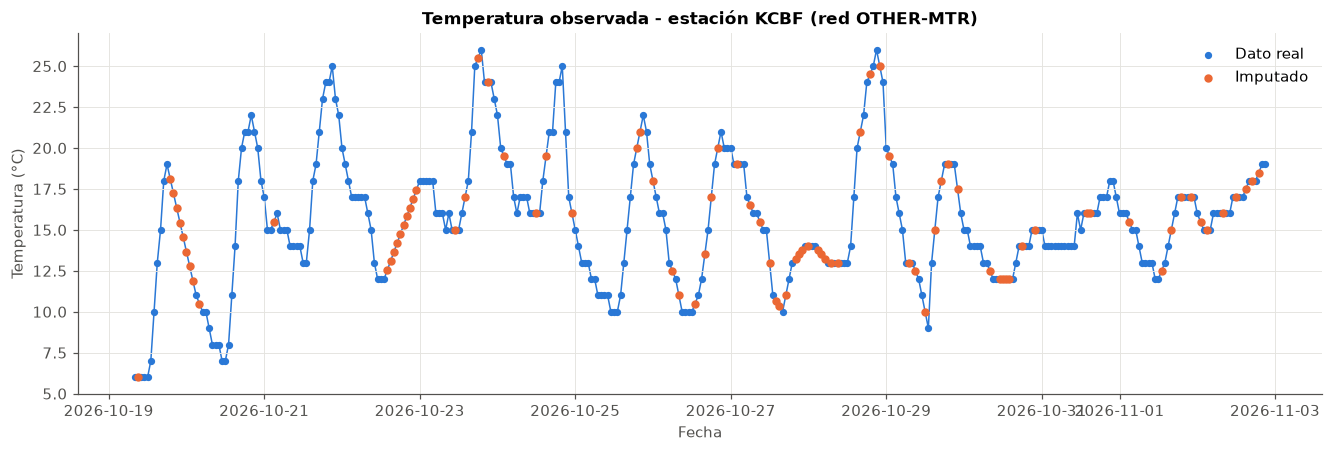

In [14]:
estacion_ejemplo = cobertura.loc[cohorte].query('hueco_max_h >= 9 and hueco_max_h <= 11').sample(1, random_state=0).index[0]
d = panel[panel['station_id'] == estacion_ejemplo]

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(d['target_hour_utc'], d['obs_temp_c'], color=AZUL, lw=1, zorder=1)
ax.scatter(d.loc[~d['obs_temp_c_imputado'], 'target_hour_utc'], d.loc[~d['obs_temp_c_imputado'], 'obs_temp_c'],
           s=14, color=AZUL, label='Dato real', zorder=2)
ax.scatter(d.loc[d['obs_temp_c_imputado'], 'target_hour_utc'], d.loc[d['obs_temp_c_imputado'], 'obs_temp_c'],
           s=20, color=NARANJA, label='Imputado', zorder=3)
ax.set(title=f'Temperatura observada - estación {estacion_ejemplo} (red {cobertura.loc[estacion_ejemplo, "red"]})',
       xlabel='Fecha', ylabel='Temperatura (°C)')
ax.legend(frameon=False)
plt.show()

### 8. Dirección del viento en sectores y hora en forma cíclica

Sólo se codifica la **hora** de forma cíclica (seno/coseno): con 15 días de datos no hay ciclos completos de semana
(168 h ≈ 2 repeticiones) ni de mes, así que un encoding de día-de-semana o mes no aportaría nada confiable -por eso quedan
afuera, a diferencia de un dataset con varios meses u años.

In [15]:
SECTORES = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']

dir_valida = panel['obs_wind_direction_d'].notna()
panel['sector_viento'] = pd.NA
panel.loc[dir_valida, 'sector_viento'] = np.array(SECTORES)[
    (((panel.loc[dir_valida, 'obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)]
panel['sector_viento'] = pd.Categorical(panel['sector_viento'], SECTORES)

panel['hora_local'] = np.nan
for tz, idx in panel.groupby('timeZone').groups.items():
    panel.loc[idx, 'hora_local'] = panel.loc[idx, 'target_hour_utc'].dt.tz_convert(tz).dt.hour
panel['hora_local'] = panel['hora_local'].astype(int)

panel['hora_sin'] = np.sin(2 * np.pi * panel['hora_local'] / 24)
panel['hora_cos'] = np.cos(2 * np.pi * panel['hora_local'] / 24)

panel[['hora_local', 'hora_sin', 'hora_cos', 'sector_viento']].head()

,hora_local,hora_sin,hora_cos,sector_viento
0,21,-0.707107,0.707107,N
1,22,-0.500000,0.866025,N
2,23,-0.258819,0.965926,N
3,0,0.000000,1.000000,N
4,1,0.258819,0.965926,N


### 9. Guardar el panel limpio

In [16]:
panel.to_csv(PROCESSED + 'panel_temporal_limpio.csv', index=False)
print(f'{PROCESSED}panel_temporal_limpio.csv: {panel.shape[0]:,} filas, {panel.shape[1]} columnas, '
      f'{panel["station_id"].nunique()} estaciones')

../data/processed/panel_temporal_limpio.csv: 165,896 filas, 23 columnas, 466 estaciones


# Tests de estacionariedad y diferenciación

La imputación de la sección anterior (interpolación lineal, acotada a huecos ≤ 12 h) usa el punto **posterior**
al hueco para rellenar los valores intermedios -usa información del futuro para completar el pasado. Esto importa de dos
formas distintas:

1. **Si esto alimentara un modelo predictivo** (sección "Feature engineering"): una feature rezagada construida sobre un
   punto imputado no es realmente "información disponible en ese momento" -es leakage en el sentido clásico de ML.
2. **Acá y ahora**: la interpolación lineal traza una recta entre dos puntos reales, así que cada punto imputado queda
   pegado a sus vecinos sin el ruido de una observación real. Eso **infla la autocorrelación de lag corto** y puede hacer
   que ADF/KPSS vean una serie más suave de lo que es. Con ~20 % de cada variable imputada, conviene medir el efecto en
   vez de asumir que no importa.

Antes de los tests, se compara el ACF calculado sobre la serie imputada ("ingenuo", el único que puede alimentar a
ADF/KPSS porque necesitan espaciado regular sin `NaN`) contra un ACF que sólo usa pares de observaciones **reales** para
cada lag. Si coinciden, la imputación no distorsiona la conclusión; si no, hay que leer los resultados con esa salvedad.

Los tests se corren sobre estaciones con **cero faltantes remanentes** tras la imputación acotada (si quedó algún hueco
> 12 h sin rellenar, ADF/KPSS no pueden correr sin romper el espaciado regular).

### Selección de estaciones de ejemplo

In [17]:
FLAGS_IMPUTADO = [f'{v}_imputado' for v in VARIABLES_CONTINUAS]

resumen_estacion = pd.DataFrame({
    'pct_imputado': panel.groupby('station_id')[FLAGS_IMPUTADO].mean().mean(axis=1) * 100,
    'pct_faltante': panel.groupby('station_id')[VARIABLES_CONTINUAS].apply(lambda g: g.isna().to_numpy().mean()) * 100,
}).join(cobertura[['red', 'estado']])

candidatas = resumen_estacion[resumen_estacion['pct_faltante'] == 0].sort_values('pct_imputado')
print(f'{len(candidatas)} de {len(cohorte)} estaciones del cohorte sin ningún faltante remanente en las 4 variables continuas')

ESTACIONES_EJEMPLO = candidatas.drop_duplicates('estado').head(4).index.tolist()
candidatas.loc[ESTACIONES_EJEMPLO]

108 de 466 estaciones del cohorte sin ningún faltante remanente en las 4 variables continuas


,pct_imputado,pct_faltante,red,estado
station_id,,,,
KMCK,9.761236,0.0,ASOS-HFM,NE
KPNC,9.901685,0.0,ASOS-HFM,OK
KLWD,9.971910,0.0,ASOS-HFM,IA
KDVL,9.971910,0.0,ASOS-HFM,ND


### ACF ingenuo vs. ACF con sólo pares reales

In [18]:
from statsmodels.tsa.stattools import acf as acf_statsmodels

NLAGS = 48


def acf_pares_completos(valores, es_imputado, nlags):
    """Autocorrelación usando, en cada lag, sólo los pares donde las DOS observaciones son reales (no imputadas)."""
    real = pd.Series(valores).where(~pd.Series(es_imputado).to_numpy())
    salida = []
    for k in range(nlags + 1):
        x, y = real, real.shift(k)
        validos = x.notna() & y.notna()
        salida.append(x[validos].corr(y[validos]) if validos.sum() > 2 else np.nan)
    return np.array(salida)


comparacion = []
for sid in ESTACIONES_EJEMPLO:
    d = panel[panel['station_id'] == sid].sort_values('target_hour_utc')
    ingenuo = acf_statsmodels(d['obs_temp_c'], nlags=NLAGS, fft=True)
    reales = acf_pares_completos(d['obs_temp_c'].values, d['obs_temp_c_imputado'].values, NLAGS)
    comparacion.append(pd.DataFrame({'lag': range(NLAGS + 1), 'ACF ingenuo': ingenuo, 'ACF pares reales': reales,
                                     'station_id': sid}))
comparacion = pd.concat(comparacion)

tabla_comparacion = (comparacion[comparacion['lag'].isin([1, 2, 3, 11, 24])]
                     .set_index(['station_id', 'lag'])[['ACF ingenuo', 'ACF pares reales']])
tabla_comparacion['diferencia'] = tabla_comparacion['ACF ingenuo'] - tabla_comparacion['ACF pares reales']
tabla_comparacion.round(3)

ACF ingenuo  ACF pares reales  diferencia
station_id lag                                           
KMCK       1          0.972             0.976      -0.004
           2          0.918             0.925      -0.007
           3          0.843             0.855      -0.012
           11         0.223             0.279      -0.057
           24         0.380             0.349       0.031
KPNC       1          0.945             0.946      -0.001
           2          0.844             0.846      -0.002
           3          0.705             0.704       0.001
           11        -0.299            -0.385       0.086
           24         0.693             0.827      -0.133
KLWD       1          0.954             0.954       0.001
           2          0.859             0.855       0.004
           3          0.725             0.714       0.010
           11        -0.314            -0.397       0.084
           24         0.675             0.792      -0.117
KDVL       1          0.973             0.973      -0.000
           2          0.919             0.920      -0.001
           3          0.847             0.847      -0.000
           11         0.343             0.401      -0.058
           24         0.546             0.556      -0.010

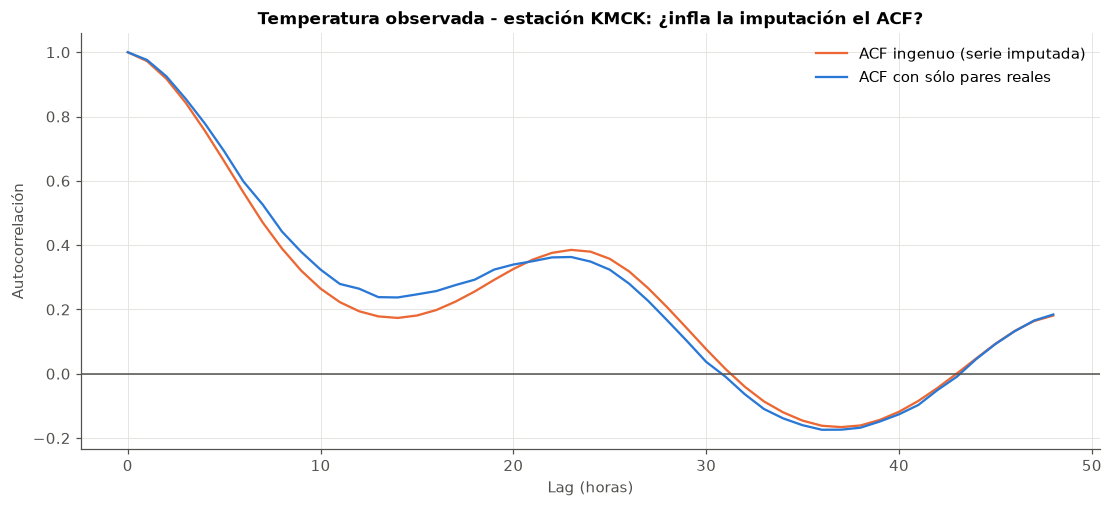

In [19]:
sid_ejemplo = ESTACIONES_EJEMPLO[0]
sub = comparacion[comparacion['station_id'] == sid_ejemplo]

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.plot(sub['lag'], sub['ACF ingenuo'], color=NARANJA, lw=1.5, label='ACF ingenuo (serie imputada)')
ax.plot(sub['lag'], sub['ACF pares reales'], color=AZUL, lw=1.5, label='ACF con sólo pares reales')
ax.axhline(0, color=GRIS_TEXTO, lw=1)
ax.set(title=f'Temperatura observada - estación {sid_ejemplo}: ¿infla la imputación el ACF?',
       xlabel='Lag (horas)', ylabel='Autocorrelación')
ax.legend(frameon=False)
plt.show()

### Tests ADF y KPSS: serie cruda, diferenciada (lag 1) y diferenciada estacional (lag 24)

In [20]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss


def test_estacionariedad(serie):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')  # adfuller: FutureWarning por el cambio de formato de retorno en statsmodels;
        # kpss: avisa cuando el p-valor cae fuera de su tabla (p<0,01 o p>0,1)
        adf_p = adfuller(serie, autolag='AIC')[1]
        kpss_p = kpss(serie, regression='c', nlags='auto')[1]
    return pd.Series({'ADF p-valor': adf_p, 'KPSS p-valor': kpss_p})


filas = []
for sid in ESTACIONES_EJEMPLO:
    d = panel[panel['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['obs_temp_c']
    for nombre, s in [('cruda', d), ('diff(1)', d.diff().dropna()), ('diff(24)', d.diff(24).dropna())]:
        r = test_estacionariedad(s)
        r['station_id'], r['transformación'] = sid, nombre
        filas.append(r)

tabla_estacionariedad = pd.DataFrame(filas).set_index(['station_id', 'transformación'])
tabla_estacionariedad.round(4)

ADF p-valor  KPSS p-valor
station_id transformación                           
KMCK       cruda                0.0066        0.1000
           diff(1)              0.0000        0.1000
           diff(24)             0.0172        0.1000
KPNC       cruda                0.1929        0.0501
           diff(1)              0.0000        0.1000
           diff(24)             0.0001        0.1000
KLWD       cruda                0.1387        0.1000
           diff(1)              0.0000        0.1000
           diff(24)             0.0029        0.1000
KDVL       cruda                0.6697        0.0699
           diff(1)              0.0000        0.1000
           diff(24)             0.0302        0.1000

### Resumen sobre todo el cohorte

Se repiten ADF y KPSS para las 4 variables continuas en las 466 estaciones del cohorte (sólo en las combinaciones
estación-variable sin ningún faltante remanente), para no sacar conclusiones de 4 estaciones sueltas.

In [21]:
resultados_cohorte = []
for sid, g in panel.groupby('station_id'):
    g = g.sort_values('target_hour_utc')
    for var in VARIABLES_CONTINUAS:
        serie = g.set_index('target_hour_utc')[var]
        if serie.isna().any():
            continue
        for nombre, s in [('cruda', serie), ('diff(1)', serie.diff().dropna()), ('diff(24)', serie.diff(24).dropna())]:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    adf_p = adfuller(s, autolag='AIC')[1]
                    kpss_p = kpss(s, regression='c', nlags='auto')[1]
            except Exception:
                continue
            resultados_cohorte.append({'station_id': sid, 'variable': var, 'transformación': nombre,
                                        'ADF rechaza raíz unitaria (p<0,05)': adf_p < 0.05,
                                        'KPSS rechaza estacionariedad (p<0,05)': kpss_p < 0.05})

resultados_cohorte = pd.DataFrame(resultados_cohorte)
print(f'{resultados_cohorte["station_id"].nunique()} estaciones distintas aportaron al menos un resultado')

resumen_cohorte = (resultados_cohorte.groupby(['variable', 'transformación'])
                   [['ADF rechaza raíz unitaria (p<0,05)', 'KPSS rechaza estacionariedad (p<0,05)']]
                   .mean().mul(100).round(1))
resumen_cohorte

127 estaciones distintas aportaron al menos un resultado


ADF rechaza raíz unitaria (p<0,05)  \
variable          transformación                                       
obs_dewpoint_c    cruda                                         28.7   
                  diff(1)                                      100.0   
                  diff(24)                                      96.7   
obs_rh_pct        cruda                                         30.8   
                  diff(1)                                      100.0   
                  diff(24)                                     100.0   
obs_temp_c        cruda                                         25.8   
                  diff(1)                                      100.0   
                  diff(24)                                     100.0   
obs_windspeed_kmh cruda                                         93.9   
                  diff(1)                                      100.0   
                  diff(24)                                      97.4   

                                  KPSS rechaza estacionariedad (p<0,05)  
variable          transformación                                         
obs_dewpoint_c    cruda                                            85.2  
                  diff(1)                                           0.0  
                  diff(24)                                          2.5  
obs_rh_pct        cruda                                            70.0  
                  diff(1)                                           0.0  
                  diff(24)                                          0.0  
obs_temp_c        cruda                                            38.7  
                  diff(1)                                           0.0  
                  diff(24)                                          0.0  
obs_windspeed_kmh cruda                                            43.5  
                  diff(1)                                           0.0  
                  diff(24)                                          2.6

### Conclusión de esta sección

**El ACF de pares reales confirma que la imputación no distorsiona los lags cortos** (diferencia de 0,000-0,012 en los
lags 1-3), que es justo donde se apoyan ADF y la diferenciación de orden 1. Sí hay una diferencia notable en el lag 11
(el borde del hueco típico de 12 h) y en el lag 24 (el ciclo diario) -ahí la imputación sí deja una marca, así que
conviene no sobre-interpretar el ACF en esos lags puntuales en la próxima sección (se van a mostrar los dos, no sólo el
ingenuo).

**El resultado no fue el que habíamos anticipado antes de correrlo.** Esperabamos que hiciera falta diferenciar en lag 24 para sacar la
estacionalidad diaria. En cambio, sobre las 466 estaciones del cohorte, en las 127 con datos completos:

- En **crudo**, ADF rechaza raíz unitaria en apenas 26-31 % de las estaciones para temperatura, HR y punto de rocío (en
  viento, más ruidoso, rechaza en 94 %). KPSS rechaza estacionariedad en 39-85 % de los casos -la mayoría de las series
  no son estacionarias en su forma cruda, como era de esperar con un ciclo diurno tan marcado.
- **Diferenciando en lag 1**, ADF rechaza raíz unitaria en el 100 % de los casos y KPSS no rechaza estacionariedad en
  ninguno, para las 4 variables. La diferenciación simple ya alcanza para que ambos tests (con hipótesis nulas opuestas)
  coincidan en que la serie es estacionaria.
- **Diferenciando en lag 24** el resultado es parecido pero levemente peor (96,7-100 % ADF, 0-2,6 % KPSS): no hace falta,
  y complica la serie sin necesidad (en vez de perder 1 observación al diferenciar se pierden 24).

Estos números no cambiaron al ampliar el cohorte de 324 a 466 estaciones: las 142 estaciones recuperadas por excluir la
ventana del corte siguen teniendo esa ventana como `NaN` sin imputar (es más larga que `UMBRAL_HUECO`), así que ninguna
de ellas entra al subconjunto "sin ningún faltante remanente" sobre el que corren estos tests -ese subconjunto es, antes
y después del cambio, el mismo grupo de estaciones que nunca tuvo un hueco largo.

La diferenciación en lag 1 es la que se va a usar de acá en adelante. Esto **no** significa que no haya estacionalidad
diaria -ADF/KPSS prueban raíz unitaria y estacionariedad de nivel, no ausencia de estructura periódica. Que una serie
diferenciada sea estacionaria para estos tests es compatible con que todavía tenga autocorrelación en el lag 24, que es
justo lo que se revisa en la próxima sección.

# Análisis de autocorrelación

ADF y KPSS ya mostraron que diferenciar en lag 1 alcanza para que ambos tests coincidan en que la serie es
estacionaria (sección anterior). Pero "estacionaria" para esos tests no es lo mismo que "sin estructura periódica": acá se
revisa, con ACF y PACF, si la diferenciación en lag 1 deja o no un resto de ciclo diario (lag 24) -y se sigue comparando
contra el ACF de sólo-pares-reales, porque ya se vio que la imputación deja una marca justo en el lag 24.

### ACF y PACF: serie cruda vs. diferenciada (lag 1)

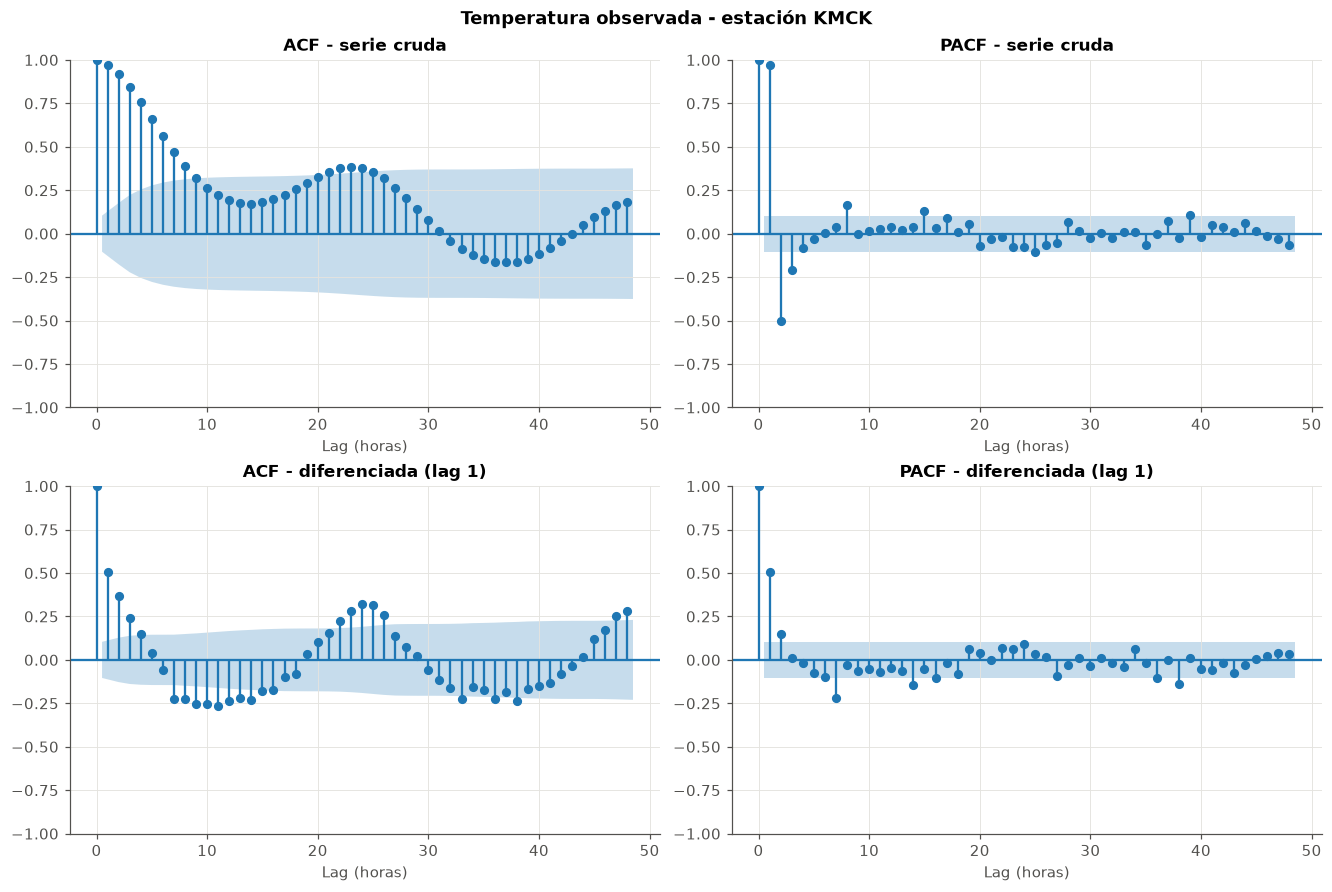

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sid = ESTACIONES_EJEMPLO[0]
serie = panel[panel['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['obs_temp_c']
serie_diff = serie.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
plot_acf(serie, lags=48, ax=axes[0, 0], title='ACF - serie cruda')
plot_pacf(serie, lags=48, ax=axes[0, 1], method='ywm', title='PACF - serie cruda')
plot_acf(serie_diff, lags=48, ax=axes[1, 0], title='ACF - diferenciada (lag 1)')
plot_pacf(serie_diff, lags=48, ax=axes[1, 1], method='ywm', title='PACF - diferenciada (lag 1)')
for ax in axes.flat:
    ax.set_xlabel('Lag (horas)')
fig.suptitle(f'Temperatura observada - estación {sid}', fontweight='bold')
figuras['13_acf_pacf_crudo_vs_diff'] = fig
plt.show()

### ¿Sigue habiendo ciclo diario tras diferenciar? ACF ingenuo vs. pares reales en los lags clave

In [23]:
LAGS_INTERES = [1, 2, 11, 12, 23, 24, 25, 48]

filas_diff = []
for sid in ESTACIONES_EJEMPLO:
    d = panel[panel['station_id'] == sid].sort_values('target_hour_utc')
    for var in VARIABLES_CONTINUAS:
        serie_diff = d[var].diff()
        # un punto de la serie diferenciada es "no confiable" si CUALQUIERA de los dos valores que lo forman fue imputado
        flag_diff = d[f'{var}_imputado'] | d[f'{var}_imputado'].shift(1).fillna(False).astype(bool)

        validos = serie_diff.notna()
        s, f = serie_diff[validos], flag_diff[validos]

        ingenuo = acf_statsmodels(s, nlags=48, fft=True)
        reales = acf_pares_completos(s.values, f.values, 48)
        for lag in LAGS_INTERES:
            filas_diff.append({'station_id': sid, 'variable': var, 'lag': lag,
                                'ACF ingenuo': ingenuo[lag], 'ACF pares reales': reales[lag]})

tabla_diff = pd.DataFrame(filas_diff)
tabla_diff['diferencia_abs'] = (tabla_diff['ACF ingenuo'] - tabla_diff['ACF pares reales']).abs()
tabla_diff.groupby('lag')['diferencia_abs'].agg(['mean', 'max']).round(3)

,mean,max
lag,,
1,0.045,0.152
2,0.024,0.079
11,0.024,0.073
12,0.014,0.066
23,0.035,0.104
24,0.047,0.127
25,0.035,0.095
48,0.046,0.115


In [24]:
tabla_diff.pivot_table(index=['variable', 'lag'], values=['ACF ingenuo', 'ACF pares reales'], aggfunc='mean').round(3)

ACF ingenuo  ACF pares reales
variable          lag                               
obs_dewpoint_c    1          0.122             0.034
                  2          0.073             0.065
                  11        -0.005             0.001
                  12        -0.037            -0.030
                  23         0.037             0.058
                  24         0.031             0.074
                  25         0.013             0.026
                  48         0.022             0.030
obs_rh_pct        1          0.245             0.217
                  2          0.192             0.182
                  11        -0.126            -0.100
                  12        -0.141            -0.132
                  23         0.259             0.288
                  24         0.288             0.322
                  25         0.243             0.262
                  48         0.220             0.263
obs_temp_c        1          0.513             0.489
                  2          0.383             0.379
                  11        -0.232            -0.200
                  12        -0.223            -0.204
                  23         0.396             0.466
                  24         0.446             0.530
                  25         0.418             0.484
                  48         0.394             0.484
obs_windspeed_kmh 1         -0.218            -0.258
                  2         -0.105            -0.078
                  11        -0.012             0.001
                  12        -0.009            -0.015
                  23         0.019            -0.001
                  24        -0.003             0.003
                  25         0.018             0.038
                  48        -0.005            -0.007

### Resumen sobre todo el cohorte: ¿cuántas estaciones conservan autocorrelación significativa?

Se calcula el ACF de la serie diferenciada (lag 1) hasta el lag 24 en las estaciones con datos completos, y se compara
contra una banda de significancia aproximada (± 1,96/√n, la que usa `statsmodels` para ruido blanco).

In [25]:
UMBRAL_SIGNIFICATIVO = 1.96 / np.sqrt(len(RANGO_COMPLETO))
print(f'Umbral de significancia aproximado (95%): ±{UMBRAL_SIGNIFICATIVO:.3f}')

resultados_acf_cohorte = []
for sid, g in panel.groupby('station_id'):
    g = g.sort_values('target_hour_utc')
    for var in VARIABLES_CONTINUAS:
        serie = g[var]
        if serie.isna().any():
            continue
        serie_diff = serie.diff().dropna()
        acf_vals = acf_statsmodels(serie_diff, nlags=24, fft=True)
        resultados_acf_cohorte.append({'station_id': sid, 'variable': var,
                                        'acf_lag1': acf_vals[1], 'acf_lag12': acf_vals[12], 'acf_lag24': acf_vals[24]})

resultados_acf_cohorte = pd.DataFrame(resultados_acf_cohorte)
for lag in ['acf_lag1', 'acf_lag12', 'acf_lag24']:
    resultados_acf_cohorte[f'{lag}_sig'] = resultados_acf_cohorte[lag].abs() > UMBRAL_SIGNIFICATIVO

print(f'{resultados_acf_cohorte["station_id"].nunique()} estaciones con datos completos aportaron resultado')
resumen_acf_cohorte = (resultados_acf_cohorte.groupby('variable')[['acf_lag1_sig', 'acf_lag12_sig', 'acf_lag24_sig']]
                       .mean().mul(100).round(1))
resumen_acf_cohorte

Umbral de significancia aproximado (95%): ±0.104


127 estaciones con datos completos aportaron resultado


,acf_lag1_sig,acf_lag12_sig,acf_lag24_sig
variable,,,
obs_dewpoint_c,50.8,10.7,45.9
obs_rh_pct,98.3,77.5,100.0
obs_temp_c,100.0,93.5,100.0
obs_windspeed_kmh,90.4,7.8,20.9


### Conclusión de esta sección

El gráfico confirma visualmente lo que mostraban los números: el ACF de la serie cruda decae lento y vuelve a subir
alrededor del lag 24 (el ciclo diario clásico). Diferenciar en lag 1 saca la mayor parte de esa persistencia de corto
plazo, pero el ACF de la serie diferenciada sigue formando una onda con picos cerca del lag 24 y valles cerca del lag 12
-se nota a simple vista, fuera de la banda de significancia en varios lags.

**La tabla sobre las 127 estaciones del cohorte (de 466) con datos completos lo confirma con números, y separa bien a
las variables:**

| Variable | lag 1 significativo | lag 12 significativo | lag 24 significativo |
|---|---|---|---|
| Temperatura | 100 % | 93,5 % | 100 % |
| Humedad relativa | 98,3 % | 77,5 % | 100 % |
| Punto de rocío | 50,8 % | 10,7 % | 45,9 % |
| Velocidad del viento | 90,4 % | 7,8 % | 20,9 % |

- **Temperatura y humedad relativa**: diferenciar en lag 1 **no** elimina el ciclo diario -en el 100 % de las estaciones
  queda autocorrelación significativa en el lag 24 (ACF ≈ 0,45-0,53 en temperatura, 0,29-0,32 en HR en las estaciones de
  ejemplo). Esto confirma la salvedad de la sección anterior: que ADF/KPSS den "estacionaria" no significa que no quede
  estructura periódica.
- **Punto de rocío**: el ciclo diario es mucho más débil y menos universal (45,9 % de las estaciones), consistente con
  que el punto de rocío depende más de advección de humedad que del calentamiento solar directo.
- **Viento**: el patrón se invierte. El lag 1 es significativo casi siempre (90,4 %), pero es sobre todo un artefacto
  mecánico de diferenciar una serie ruidosa (la diferenciación induce autocorrelación negativa en lag 1 incluso en ruido
  blanco). El lag 24 es significativo en sólo 20,9 % de las estaciones -coherente con lo visto en relaciones-bivariadas.ipynb:
  el viento depende más de sistemas sinópticos que del ciclo solar diario.

**Para la sección de Feature engineering**, esto dice qué variables necesitan una feature de lag 24 (o el encoding cíclico
de hora que ya está en el panel) además del lag 1: temperatura y HR claramente sí; punto de rocío y viento, mucho menos.

**Sobre la comparación ACF ingenuo vs. pares reales** (la pregunta de leakage de la sección anterior): la divergencia
media por lag es chica (0,01-0,05) pero el máximo entre estaciones/variables llega a 0,15 -no es despreciable. La
dirección del sesgo no es sistemática (a veces el ingenuo sobreestima, a veces subestima), así que no invalida la
conclusión de arriba, pero sí es una razón más para no leer un ACF puntual como un valor exacto cuando ~20 % de la serie
es imputada: hay que mirar el patrón general (la onda en el lag 24), no un número aislado.

# Feature engineering

- Variables de rezago (lags) para las variables observadas: lags 1 y 24 para temperatura y hum relativa, lag 1 para dewpoint y wind direction 
- Rolling features
- Encoding cíclico para variables circulares
- Features espaciales: correlación información de estaciones vecinas (ej: mean(temp_obs LAGGED de k vecinas más cercanas por estación))

### 1. Lags (1 y 24) para las variables observadas

Según la sección de autocorrelación: temperatura y humedad relativa necesitan lag 1 **y** lag 24 (ciclo diario
significativo en el 100 % de las estaciones incluso después de diferenciar en lag 1); punto de rocío y dirección del
viento, sólo lag 1 (su ciclo diario es mucho más débil y menos universal).

Cada feature de lag se acompaña de un flag `_imputado` (`True` si el valor del que proviene el lag fue imputado, no una
observación real) para poder filtrarlo o tratarlo distinto más adelante -la misma lógica de leakage que se discutió antes
de los tests de estacionariedad.

La dirección del viento es circular, pero un `shift` no necesita aritmética circular (a diferencia de un `diff`): sólo
"copia" el valor de una fila anterior, no resta ángulos. Por eso se puede laguear el ángulo crudo sin problema; lo que sí
se maneja con cuidado es el encoding cíclico de la sección 3.

In [26]:
def _flag_lag(variable_imputado, lag):
    """Flag de leakage para una feature de lag: True si el valor de origen (lag horas atrás) fue imputado."""
    return panel.groupby('station_id')[variable_imputado].shift(lag).fillna(False).astype(bool)


VARIABLES_LAG24 = ['obs_temp_c', 'obs_rh_pct']  # únicas con ciclo diario casi universal tras diff(1) (sección anterior)
VARIABLES_LAG1_SOLO = ['obs_dewpoint_c', 'obs_wind_direction_d']

for var in VARIABLES_LAG24 + VARIABLES_LAG1_SOLO:
    panel[f'{var}_lag1'] = panel.groupby('station_id')[var].shift(1)
    panel[f'{var}_lag1_imputado'] = _flag_lag(f'{var}_imputado', 1)

for var in VARIABLES_LAG24:
    panel[f'{var}_lag24'] = panel.groupby('station_id')[var].shift(24)
    panel[f'{var}_lag24_imputado'] = _flag_lag(f'{var}_imputado', 24)

print(f'Lag 1: {len(VARIABLES_LAG24) + len(VARIABLES_LAG1_SOLO)} variables. Lag 24: {len(VARIABLES_LAG24)} variables.')

Lag 1: 4 variables. Lag 24: 2 variables.


### 2. Rolling features

Promedio móvil de las últimas 3 horas, para las 4 variables continuas: suaviza el ruido hora a hora sin diluir del todo
la dinámica reciente (en la sección de ACF, los lags 2-3 todavía mostraban autocorrelación alta antes de diferenciar).

La ventana se calcula sobre el **shift(1)** de la serie, no sobre la serie misma: si no se corre un paso, la media móvil
de la hora *t* incluiría el propio valor de *t* -la misma lógica de "no usar información que todavía no está disponible"
que ya se aplicó en los lags. Por eso esta media cubre las horas *t-1, t-2, t-3*, no *t, t-1, t-2*.

El flag `_imputado` acá es `True` si **alguna** de las horas que entran en la ventana fue imputada.

In [27]:
VENTANA_ROLLING = 3  # horas

for var in VARIABLES_CONTINUAS:
    panel[f'{var}_roll{VENTANA_ROLLING}_mean'] = panel.groupby('station_id')[var].transform(
        lambda s: s.shift(1).rolling(VENTANA_ROLLING, min_periods=1).mean())
    panel[f'{var}_roll{VENTANA_ROLLING}_mean_imputado'] = panel.groupby('station_id')[f'{var}_imputado'].transform(
        lambda s: s.shift(1).fillna(False).rolling(VENTANA_ROLLING, min_periods=1).max()).astype(bool)

print(f'Rolling mean ({VENTANA_ROLLING} h, sobre shift(1)) agregado para {len(VARIABLES_CONTINUAS)} variables continuas.')

Rolling mean (3 h, sobre shift(1)) agregado para 4 variables continuas.


### 3. Encoding cíclico para la dirección del viento

La hora ya se codificó de forma cíclica en la limpieza (`hora_sin`/`hora_cos`, sección 8). La otra variable circular del
panel es la dirección del viento: `sector_viento` la discretiza en 8 sectores categóricos, pero para un modelo que use
features numéricas conviene además una versión continua seno/coseno -con la misma idea de que 350° y 10° tienen que
quedar cerca en el espacio de features, no en los extremos opuestos de una escala de 0 a 360.

In [28]:
panel['obs_wind_direction_sin'] = np.sin(np.deg2rad(panel['obs_wind_direction_d']))
panel['obs_wind_direction_cos'] = np.cos(np.deg2rad(panel['obs_wind_direction_d']))

# Mismo flag de leakage que el lag 1 crudo: viene de la misma fila de origen (t-1), sólo cambia el encoding
panel['obs_wind_direction_sin_lag1'] = panel.groupby('station_id')['obs_wind_direction_sin'].shift(1)
panel['obs_wind_direction_cos_lag1'] = panel.groupby('station_id')['obs_wind_direction_cos'].shift(1)
panel['obs_wind_direction_sin_lag1_imputado'] = panel['obs_wind_direction_d_lag1_imputado']
panel['obs_wind_direction_cos_lag1_imputado'] = panel['obs_wind_direction_d_lag1_imputado']

panel[['obs_wind_direction_d', 'obs_wind_direction_sin', 'obs_wind_direction_cos',
       'obs_wind_direction_sin_lag1', 'obs_wind_direction_cos_lag1']].head()

,obs_wind_direction_d,obs_wind_direction_sin,obs_wind_direction_cos,obs_wind_direction_sin_lag1,obs_wind_direction_cos_lag1
0,0.0,0.0,1.0,NaN,NaN
1,0.0,0.0,1.0,0.0,1.0
2,0.0,0.0,1.0,0.0,1.0
3,0.0,0.0,1.0,0.0,1.0
4,0.0,0.0,1.0,0.0,1.0


### 4. Features espaciales: promedio de las K estaciones vecinas más cercanas

Para cada estación, se buscan las `K` estaciones más cercanas (distancia euclídea sobre latitud/longitud -una
aproximación razonable para rankear vecinas a esta escala continental, no para medir distancia real en km) **dentro del
cohorte**: son las únicas con la serie regularizada e imputada en `panel`, así que son las únicas para las que tiene
sentido construir un lag.

El feature es el promedio, entre esas `K` vecinas, del **lag 1** de cada variable (no el valor crudo de la misma hora):
usar el valor de la hora *t* de una vecina para predecir la hora *t* de la estación en cuestión sería, de nuevo,
información que en la práctica no está más disponible que la propia observación que se quiere explicar.

In [29]:
from scipy.spatial.distance import cdist

K_VECINAS = 2
coords = atributos_estacion.loc[cohorte, ['latitud', 'longitud']]
dist_matrix = pd.DataFrame(cdist(coords, coords), index=coords.index, columns=coords.index)
vecinas = {e: dist_matrix.loc[e].drop(e).nsmallest(K_VECINAS).index.tolist() for e in coords.index}

# Continuas con lag1 ya calculado; la dirección del viento queda afuera: promediar ángulos crudos entre vecinas no
# tiene sentido (es la misma razón por la que se encodeó seno/coseno en la sección 3)
VARIABLES_ESPACIALES = ['obs_temp_c', 'obs_rh_pct', 'obs_dewpoint_c']

for var in VARIABLES_ESPACIALES:
    pivot_lag1 = panel.pivot(index='target_hour_utc', columns='station_id', values=f'{var}_lag1')
    pivot_imputado = panel.pivot(index='target_hour_utc', columns='station_id', values=f'{var}_lag1_imputado')

    col_mean, col_imp = f'{var}_vecinas_lag1_mean', f'{var}_vecinas_lag1_mean_imputado'
    vecinas_mean = pd.DataFrame({e: pivot_lag1[vecinas[e]].mean(axis=1) for e in coords.index}).rename_axis('target_hour_utc')
    vecinas_imputado = pd.DataFrame({e: pivot_imputado[vecinas[e]].any(axis=1) for e in coords.index}).rename_axis('target_hour_utc')

    panel = panel.merge(
        vecinas_mean.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_mean),
        on=['target_hour_utc', 'station_id'], how='left')
    panel = panel.merge(
        vecinas_imputado.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_imp),
        on=['target_hour_utc', 'station_id'], how='left')

print(f'K={K_VECINAS} vecinas por estación (distancia euclídea lat/long). Features espaciales: {VARIABLES_ESPACIALES}')
panel[[f'{v}_vecinas_lag1_mean' for v in VARIABLES_ESPACIALES]].describe().T[['count', 'mean', 'std']]

K=2 vecinas por estación (distancia euclídea lat/long). Features espaciales: ['obs_temp_c', 'obs_rh_pct', 'obs_dewpoint_c']


,count,mean,std
obs_temp_c_vecinas_lag1_mean,158931.0,14.865698,6.465794
obs_rh_pct_vecinas_lag1_mean,158910.0,74.596314,19.011738
obs_dewpoint_c_vecinas_lag1_mean,158992.0,9.661954,5.337043


### 5. Resumen de features y guardado

Antes de guardar, un chequeo rápido: cuánto falta y cuánto está "contaminado" por imputación en cada feature nueva. Se
espera más `NaN` en los lag 24 (24 h de calentamiento al principio de cada estación, contra 1 h en los lag 1) y una tasa
de `_imputado` parecida al ~20 % que ya tenía cada variable de origen.

In [30]:
FEATURES_CON_FLAG = (
    [f'{v}_lag1' for v in VARIABLES_LAG24 + VARIABLES_LAG1_SOLO] +
    [f'{v}_lag24' for v in VARIABLES_LAG24] +
    [f'{v}_roll{VENTANA_ROLLING}_mean' for v in VARIABLES_CONTINUAS] +
    ['obs_wind_direction_sin_lag1', 'obs_wind_direction_cos_lag1'] +
    [f'{v}_vecinas_lag1_mean' for v in VARIABLES_ESPACIALES]
)

resumen_features = pd.DataFrame({
    'faltante_pct': panel[FEATURES_CON_FLAG].isna().mean().mul(100).round(1),
    'imputado_pct': pd.Series({f: 100 * panel[f'{f}_imputado'].mean() for f in FEATURES_CON_FLAG}).round(1),
})
resumen_features

,faltante_pct,imputado_pct
obs_temp_c_lag1,10.9,20.3
obs_rh_pct_lag1,10.9,20.9
obs_dewpoint_c_lag1,10.8,19.9
obs_wind_direction_d_lag1,10.5,20.4
obs_temp_c_lag24,17.2,18.6
obs_rh_pct_lag24,17.3,19.2
obs_temp_c_roll3_mean,10.6,41.4
obs_rh_pct_roll3_mean,10.7,42.3
obs_windspeed_kmh_roll3_mean,10.3,41.1
obs_dewpoint_c_roll3_mean,10.5,40.8


In [31]:
panel.to_csv(PROCESSED + 'panel_features.csv', index=False)
print(f'{PROCESSED}panel_features.csv: {panel.shape[0]:,} filas, {panel.shape[1]} columnas, '
      f'{panel["station_id"].nunique()} estaciones')

../data/processed/panel_features.csv: 165,896 filas, 55 columnas, 466 estaciones
